## Import libraries

In [1]:
# Fundamentals
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from glob import glob

# ObsPy functions
from obspy import read, UTCDateTime as utc
from obspy.geodetics.base import gps2dist_azimuth
from obspy.signal.cross_correlation import correlate_template

# Font
import matplotlib as mpl
import matplotlib.font_manager as font_manager
font_dir = ['/home/msseo/Download/Helvetica']
for font in font_manager.findSystemFonts(font_dir):
    font_manager.fontManager.addfont(font)

mpl.rcParams['font.family']="helvetica"
mpl.rcParams['axes.unicode_minus']=False

## Load event catalog

In [2]:
event_catalog=pd.read_csv("/home/msseo/works/72.2025_Imsil_swarm/event_catalog/Imsil_catalog.csv", sep=",")
event_catalog.head()

,Year,Month,Day,Hour,Minute,Second,Latitude,Longitude,Depth,Magnitude
0,2025,11,3,5,5,39,35.55,127.29,13,1.4
1,2025,11,3,5,6,25,35.55,127.29,12,1.4
2,2025,11,3,5,10,44,35.55,127.30,13,1.3
3,2025,11,3,5,23,39,35.56,127.30,13,1.5
4,2025,11,3,5,24,12,35.55,127.29,14,1.5


In [3]:
year_list, month_list, day_list, hour_list, minute_list, second_list=[], [], [], [], [], []
for i in range(len(event_catalog)):
    year, month, day=event_catalog["Year"][i], event_catalog["Month"][i], event_catalog["Day"][i]
    hour, minute, second=event_catalog["Hour"][i], event_catalog["Minute"][i], event_catalog["Second"][i]
    origin_time_kst=utc(year, month, day, hour, minute, second)
    origin_time_utc=origin_time_kst-9*3600
    year, month, day=origin_time_utc.year, origin_time_utc.month, origin_time_utc.day
    hour, monute, second=origin_time_utc.hour, origin_time_utc.minute, origin_time_utc.second
    year_list.append(year)
    month_list.append(month)
    day_list.append(day)
    hour_list.append(hour)
    minute_list.append(minute)
    second_list.append(second)
event_catalog["Year"]=year_list
event_catalog["Month"]=month_list
event_catalog["Day"]=day_list
event_catalog["Hour"]=hour_list
event_catalog["Minute"]=minute_list
event_catalog["Second"]=second_list
event_catalog.to_csv("/home/msseo/works/72.2025_Imsil_swarm/event_catalog/event_catalog_utc.csv", index=False)

## Read waveforms and plot

### Highpass filter (1 Hz)

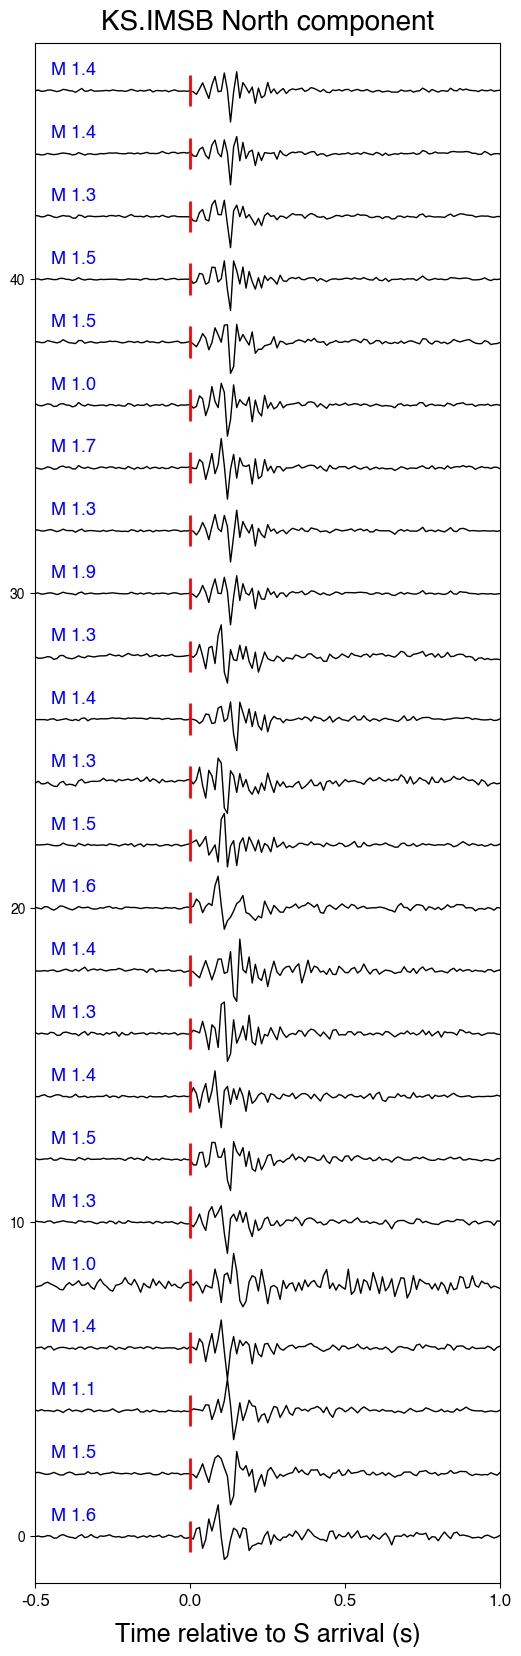

In [26]:
count_list, sp_ratio_list=[], []
sacfile_list=sorted(glob("/home/msseo/works/72.2025_Imsil_swarm/waveforms_100km/20*/*IMSB*HHN.sac"))[::-1]
plt.figure(figsize=(6, 20))
plt.title("KS.IMSB North component", fontsize=20, pad=10)
count=0
for i in range(len(sacfile_list)):
    tr_N=read(sacfile_list[i])[0]
    try:
        # p_time=tr_Z.stats.starttime-tr_Z.stats.sac.b+tr_Z.stats.sac.a
        s_time=tr_N.stats.starttime-tr_N.stats.sac.b+tr_N.stats.sac.t0
        # ps_time=tr_Z.stats.sac.t0-tr_Z.stats.sac.a
        tr_N_slice=tr_N.copy().detrend("demean").taper(0.05).filter("highpass", freq=1, corners=6, zerophase=True).slice(s_time-0.5, s_time+1.0).detrend("demean").normalize()
        plt.plot(tr_N_slice.times(), tr_N_slice.data+2*count, color="k", lw=1)
        plt.vlines(x=0.5, ymin=2*count-0.5, ymax=2*count+0.5, color="r", lw=2)
        # plt.vlines(x=0.9, ymin=2*count-0.5, ymax=2*count+0.5, color="r", lw=2)
        # plt.vlines(x=ps_time+0.5, ymin=2*count-0.5, ymax=2*count+0.5, color="b", lw=2)
        # plt.vlines(x=ps_time+0.9, ymin=2*count-0.5, ymax=2*count+0.5, color="b", lw=2)
        
        # s_slice=tr_Z.copy().detrend("demean").taper(0.05).slice(p_time, p_time+0.3)
        s_slice=tr_N.copy().detrend("demean").taper(0.05).slice(s_time, s_time+0.3)
        # p_rms=np.sqrt(np.mean(p_slice.data**2))
        s_rms=np.sqrt(np.mean(s_slice.data**2))
        # sp_ratio=s_rms/p_rms
        # sp_ratio=np.log10(s_rms/p_rms)
        mag=np.array(event_catalog["Magnitude"])[::-1][i]
        plt.text(x=0.05, y=2*count+0.5, s=f"M {mag:.1f}", color="b", fontsize=13)
        count_list.append(count)
        # sp_ratio_list.append(sp_ratio)
        count += 1
    except:
        pass
    
plt.xlim(0, 1.5)
plt.ylim(-1.5, 47.5)
plt.xticks(np.arange(0.0, 2.0, 0.5), np.arange(-0.5, 1.5, 0.5), fontsize=12)
# plt.yticks([])
plt.xlabel("Time relative to S arrival (s)", fontsize=18, labelpad=10)
plt.show();

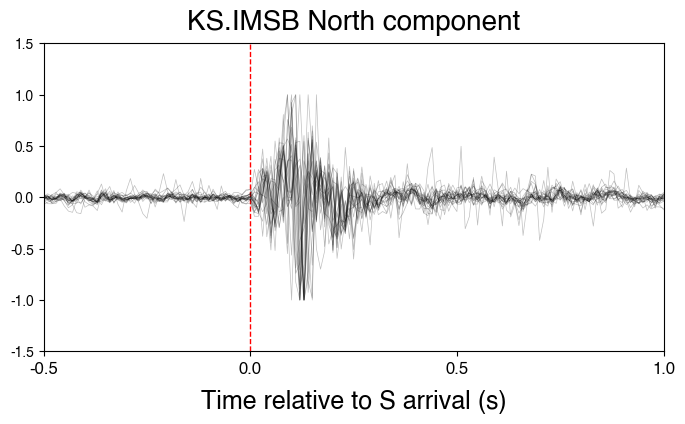

In [27]:
count_list, sp_ratio_list=[], []
sacfile_list=sorted(glob("/home/msseo/works/72.2025_Imsil_swarm/waveforms_100km/20*/*IMSB*HHN.sac"))[::-1]
plt.figure(figsize=(8, 4))
plt.title("KS.IMSB North component", fontsize=20, pad=10)

plt.vlines(x=0.5, ymin=-1.5, ymax=1.5, color="r", lw=1, linestyle="--")

count=0
for i in range(len(sacfile_list)):
    tr_N=read(sacfile_list[i])[0]
    try:
        # p_time=tr_Z.stats.starttime-tr_Z.stats.sac.b+tr_Z.stats.sac.a
        s_time=tr_N.stats.starttime-tr_N.stats.sac.b+tr_N.stats.sac.t0
        # ps_time=tr_Z.stats.sac.t0-tr_Z.stats.sac.a
        tr_N_slice=tr_N.copy().detrend("demean").taper(0.05).filter("highpass", freq=1, corners=6, zerophase=True).slice(s_time-0.5, s_time+1.0).detrend("demean").normalize()
        plt.plot(tr_N_slice.times(), tr_N_slice.data, color="k", lw=0.5, alpha=0.25)
        
        # p_slice=tr_Z.copy().detrend("demean").taper(0.05).slice(p_time, p_time+0.3)
        s_slice=tr_Z.copy().detrend("demean").taper(0.05).slice(s_time, s_time+0.3)
        # p_rms=np.sqrt(np.mean(p_slice.data**2))
        s_rms=np.sqrt(np.mean(s_slice.data**2))
        # sp_ratio=s_rms/p_rms
        # sp_ratio=np.log10(s_rms/p_rms)
        mag=np.array(event_catalog["Magnitude"])[::-1][i]
        # plt.text(x=0.05, y=2*count+0.5, s=f"M {mag:.1f}", color="b", fontsize=13)
        count_list.append(count)
        # sp_ratio_list.append(sp_ratio)
        count += 1
    except:
        pass
    
plt.xlim(0, 1.5)
plt.ylim(-1.5, 1.5)
plt.xticks(np.arange(0.0, 2.0, 0.5), np.arange(-0.5, 1.5, 0.5), fontsize=12)
# plt.yticks([])
plt.xlabel("Time relative to S arrival (s)", fontsize=18, labelpad=10)
plt.show();

### Bandpass filter (5-25 Hz)

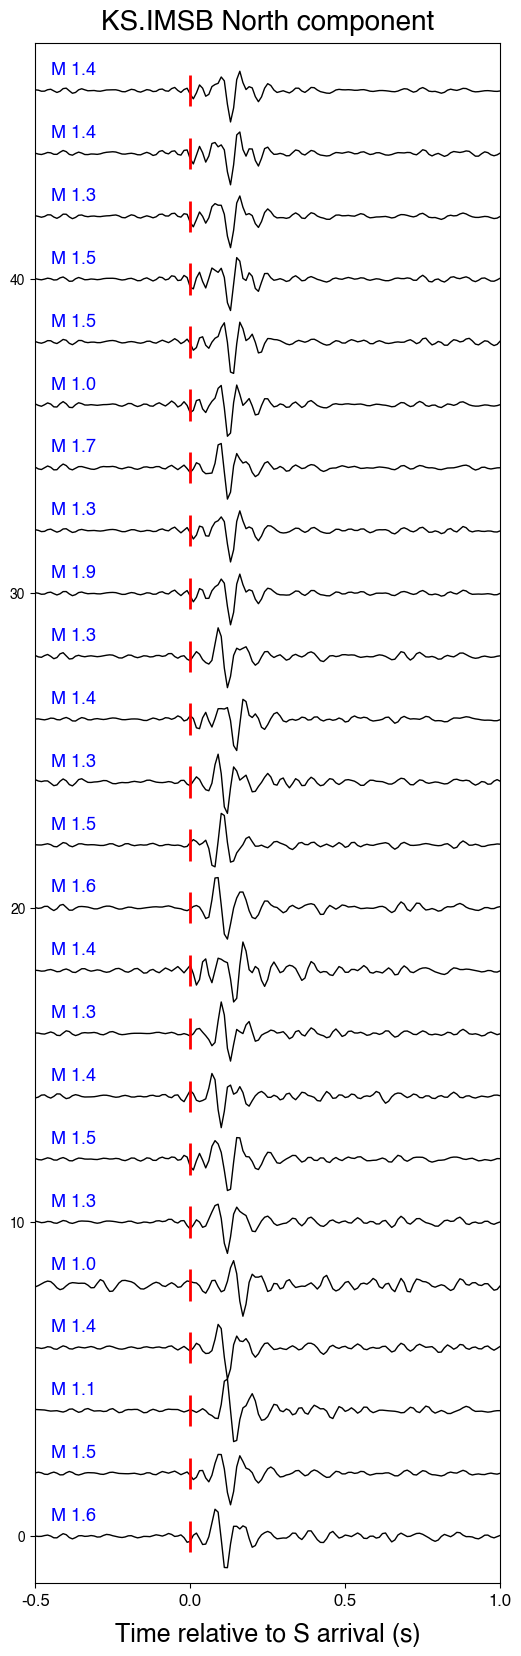

In [28]:
count_list, sp_ratio_list=[], []
sacfile_list=sorted(glob("/home/msseo/works/72.2025_Imsil_swarm/waveforms_100km/20*/*IMSB*HHN.sac"))[::-1]
plt.figure(figsize=(6, 20))
plt.title("KS.IMSB North component", fontsize=20, pad=10)
count=0
for i in range(len(sacfile_list)):
    tr_N=read(sacfile_list[i])[0]
    try:
        # p_time=tr_Z.stats.starttime-tr_Z.stats.sac.b+tr_Z.stats.sac.a
        s_time=tr_N.stats.starttime-tr_N.stats.sac.b+tr_N.stats.sac.t0
        # ps_time=tr_Z.stats.sac.t0-tr_Z.stats.sac.a
        tr_N_slice=tr_N.copy().detrend("demean").taper(0.05).filter("bandpass", freqmin=5, freqmax=25, corners=6, zerophase=True).slice(s_time-0.5, s_time+1.0).detrend("demean").normalize()
        plt.plot(tr_N_slice.times(), tr_N_slice.data+2*count, color="k", lw=1)
        plt.vlines(x=0.5, ymin=2*count-0.5, ymax=2*count+0.5, color="r", lw=2)
        # plt.vlines(x=0.9, ymin=2*count-0.5, ymax=2*count+0.5, color="r", lw=2)
        # plt.vlines(x=ps_time+0.5, ymin=2*count-0.5, ymax=2*count+0.5, color="b", lw=2)
        # plt.vlines(x=ps_time+0.9, ymin=2*count-0.5, ymax=2*count+0.5, color="b", lw=2)
        
        # s_slice=tr_Z.copy().detrend("demean").taper(0.05).slice(p_time, p_time+0.3)
        s_slice=tr_N.copy().detrend("demean").taper(0.05).slice(s_time, s_time+0.3)
        # p_rms=np.sqrt(np.mean(p_slice.data**2))
        s_rms=np.sqrt(np.mean(s_slice.data**2))
        # sp_ratio=s_rms/p_rms
        # sp_ratio=np.log10(s_rms/p_rms)
        mag=np.array(event_catalog["Magnitude"])[::-1][i]
        plt.text(x=0.05, y=2*count+0.5, s=f"M {mag:.1f}", color="b", fontsize=13)
        count_list.append(count)
        # sp_ratio_list.append(sp_ratio)
        count += 1
    except:
        pass
    
plt.xlim(0, 1.5)
plt.ylim(-1.5, 47.5)
plt.xticks(np.arange(0.0, 2.0, 0.5), np.arange(-0.5, 1.5, 0.5), fontsize=12)
# plt.yticks([])
plt.xlabel("Time relative to S arrival (s)", fontsize=18, labelpad=10)
plt.show();

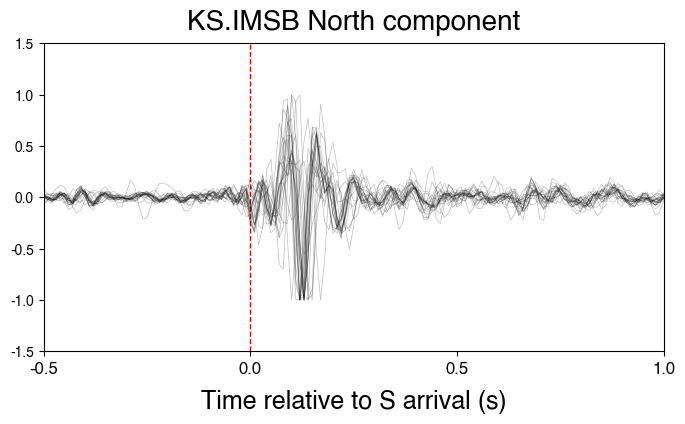

In [29]:
count_list, sp_ratio_list=[], []
sacfile_list=sorted(glob("/home/msseo/works/72.2025_Imsil_swarm/waveforms_100km/20*/*IMSB*HHN.sac"))[::-1]
plt.figure(figsize=(8, 4))
plt.title("KS.IMSB North component", fontsize=20, pad=10)

plt.vlines(x=0.5, ymin=-1.5, ymax=1.5, color="r", lw=1, linestyle="--")

count=0
for i in range(len(sacfile_list)):
    tr_N=read(sacfile_list[i])[0]
    try:
        # p_time=tr_Z.stats.starttime-tr_Z.stats.sac.b+tr_Z.stats.sac.a
        s_time=tr_N.stats.starttime-tr_N.stats.sac.b+tr_N.stats.sac.t0
        # ps_time=tr_Z.stats.sac.t0-tr_Z.stats.sac.a
        tr_N_slice=tr_N.copy().detrend("demean").taper(0.05).filter("bandpass", freqmin=5, freqmax=25, corners=6, zerophase=True).slice(s_time-0.5, s_time+1.0).detrend("demean").normalize()
        plt.plot(tr_N_slice.times(), tr_N_slice.data, color="k", lw=0.5, alpha=0.25)
        
        # p_slice=tr_Z.copy().detrend("demean").taper(0.05).slice(p_time, p_time+0.3)
        s_slice=tr_Z.copy().detrend("demean").taper(0.05).slice(s_time, s_time+0.3)
        # p_rms=np.sqrt(np.mean(p_slice.data**2))
        s_rms=np.sqrt(np.mean(s_slice.data**2))
        # sp_ratio=s_rms/p_rms
        # sp_ratio=np.log10(s_rms/p_rms)
        mag=np.array(event_catalog["Magnitude"])[::-1][i]
        # plt.text(x=0.05, y=2*count+0.5, s=f"M {mag:.1f}", color="b", fontsize=13)
        count_list.append(count)
        # sp_ratio_list.append(sp_ratio)
        count += 1
    except:
        pass
    
plt.xlim(0, 1.5)
plt.ylim(-1.5, 1.5)
plt.xticks(np.arange(0.0, 2.0, 0.5), np.arange(-0.5, 1.5, 0.5), fontsize=12)
# plt.yticks([])
plt.xlabel("Time relative to S arrival (s)", fontsize=18, labelpad=10)
plt.show();

### Bandpass filter (2-10 Hz)

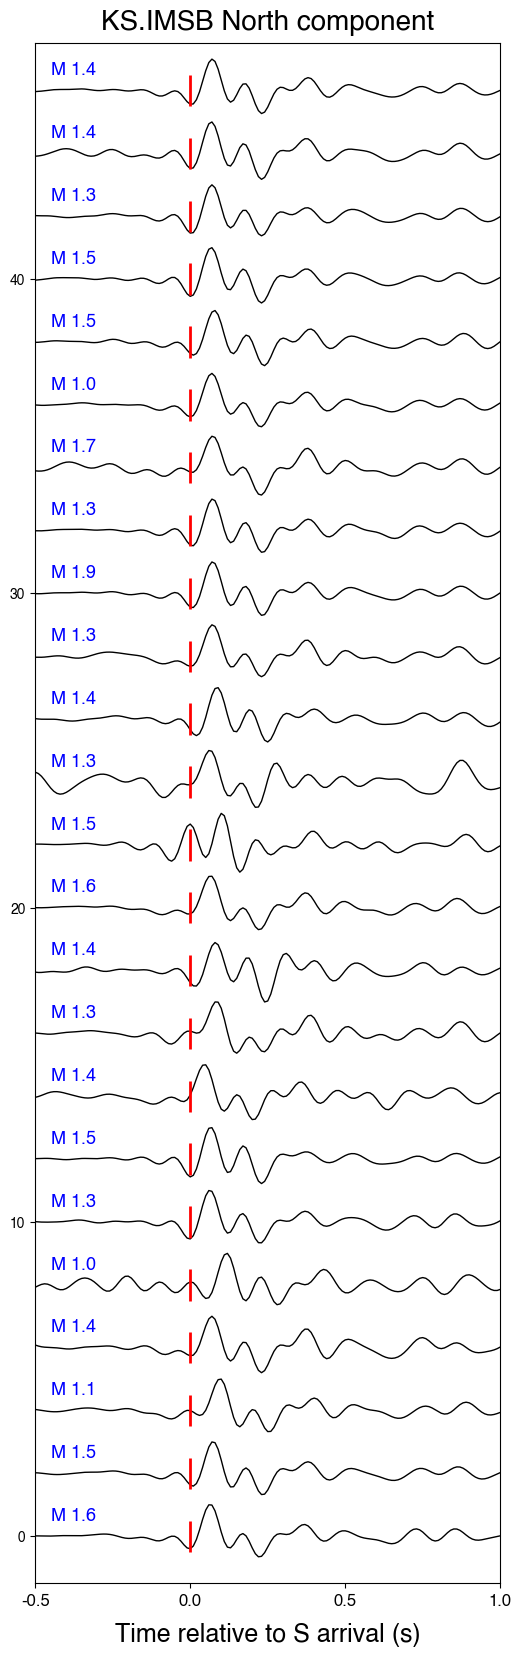

In [30]:
count_list, sp_ratio_list=[], []
sacfile_list=sorted(glob("/home/msseo/works/72.2025_Imsil_swarm/waveforms_100km/20*/*IMSB*HHN.sac"))[::-1]
plt.figure(figsize=(6, 20))
plt.title("KS.IMSB North component", fontsize=20, pad=10)
count=0
for i in range(len(sacfile_list)):
    tr_N=read(sacfile_list[i])[0]
    try:
        # p_time=tr_Z.stats.starttime-tr_Z.stats.sac.b+tr_Z.stats.sac.a
        s_time=tr_N.stats.starttime-tr_N.stats.sac.b+tr_N.stats.sac.t0
        # ps_time=tr_Z.stats.sac.t0-tr_Z.stats.sac.a
        tr_N_slice=tr_N.copy().detrend("demean").taper(0.05).filter("bandpass", freqmin=2, freqmax=10, corners=6, zerophase=True).slice(s_time-0.5, s_time+1.0).detrend("demean").normalize()
        plt.plot(tr_N_slice.times(), tr_N_slice.data+2*count, color="k", lw=1)
        plt.vlines(x=0.5, ymin=2*count-0.5, ymax=2*count+0.5, color="r", lw=2)
        # plt.vlines(x=0.9, ymin=2*count-0.5, ymax=2*count+0.5, color="r", lw=2)
        # plt.vlines(x=ps_time+0.5, ymin=2*count-0.5, ymax=2*count+0.5, color="b", lw=2)
        # plt.vlines(x=ps_time+0.9, ymin=2*count-0.5, ymax=2*count+0.5, color="b", lw=2)
        
        # s_slice=tr_Z.copy().detrend("demean").taper(0.05).slice(p_time, p_time+0.3)
        s_slice=tr_N.copy().detrend("demean").taper(0.05).slice(s_time, s_time+0.3)
        # p_rms=np.sqrt(np.mean(p_slice.data**2))
        s_rms=np.sqrt(np.mean(s_slice.data**2))
        # sp_ratio=s_rms/p_rms
        # sp_ratio=np.log10(s_rms/p_rms)
        mag=np.array(event_catalog["Magnitude"])[::-1][i]
        plt.text(x=0.05, y=2*count+0.5, s=f"M {mag:.1f}", color="b", fontsize=13)
        count_list.append(count)
        # sp_ratio_list.append(sp_ratio)
        count += 1
    except:
        pass
    
plt.xlim(0, 1.5)
plt.ylim(-1.5, 47.5)
plt.xticks(np.arange(0.0, 2.0, 0.5), np.arange(-0.5, 1.5, 0.5), fontsize=12)
# plt.yticks([])
plt.xlabel("Time relative to S arrival (s)", fontsize=18, labelpad=10)
plt.show();

In [31]:
count

24

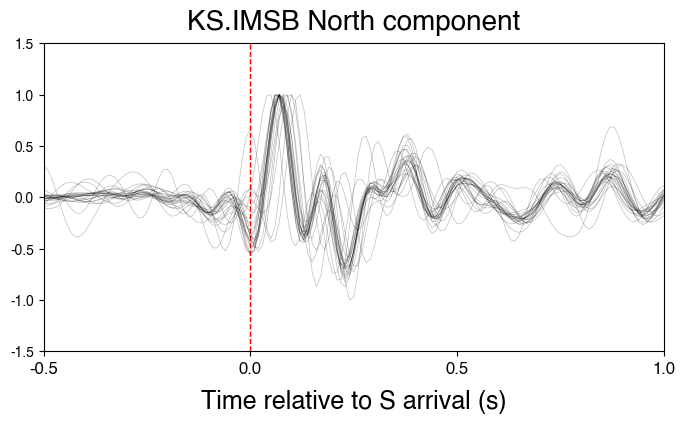

In [32]:
count_list, sp_ratio_list=[], []
sacfile_list=sorted(glob("/home/msseo/works/72.2025_Imsil_swarm/waveforms_100km/20*/*IMSB*HHN.sac"))[::-1]
plt.figure(figsize=(8, 4))
plt.title("KS.IMSB North component", fontsize=20, pad=10)

plt.vlines(x=0.5, ymin=-1.5, ymax=1.5, color="r", lw=1, linestyle="--")

count=0
for i in range(len(sacfile_list)):
    tr_N=read(sacfile_list[i])[0]
    try:
        # p_time=tr_Z.stats.starttime-tr_Z.stats.sac.b+tr_Z.stats.sac.a
        s_time=tr_N.stats.starttime-tr_N.stats.sac.b+tr_N.stats.sac.t0
        # ps_time=tr_Z.stats.sac.t0-tr_Z.stats.sac.a
        tr_N_slice=tr_N.copy().detrend("demean").taper(0.05).filter("bandpass", freqmin=2, freqmax=10, corners=6, zerophase=True).slice(s_time-0.5, s_time+1.0).detrend("demean").normalize()
        plt.plot(tr_N_slice.times(), tr_N_slice.data, color="k", lw=0.5, alpha=0.25)
        
        # p_slice=tr_Z.copy().detrend("demean").taper(0.05).slice(p_time, p_time+0.3)
        s_slice=tr_Z.copy().detrend("demean").taper(0.05).slice(s_time, s_time+0.3)
        # p_rms=np.sqrt(np.mean(p_slice.data**2))
        s_rms=np.sqrt(np.mean(s_slice.data**2))
        # sp_ratio=s_rms/p_rms
        # sp_ratio=np.log10(s_rms/p_rms)
        mag=np.array(event_catalog["Magnitude"])[::-1][i]
        # plt.text(x=0.05, y=2*count+0.5, s=f"M {mag:.1f}", color="b", fontsize=13)
        count_list.append(count)
        # sp_ratio_list.append(sp_ratio)
        count += 1
    except:
        pass
    
plt.xlim(0, 1.5)
plt.ylim(-1.5, 1.5)
plt.xticks(np.arange(0.0, 2.0, 0.5), np.arange(-0.5, 1.5, 0.5), fontsize=12)
# plt.yticks([])
plt.xlabel("Time relative to S arrival (s)", fontsize=18, labelpad=10)
plt.show();

## Calculate CC

### Highpass filter (1 Hz)

In [4]:
sacfile_list = sorted(glob("/home/msseo/works/72.2025_Imsil_swarm/waveforms_100km/20*/*IMSB*HHN.sac"))[::-1]

try:
    magnitudes = np.array(event_catalog["Magnitude"])[::-1]
except NameError:
    print("오류: 'event_catalog'가 정의되지 않았습니다. 샘플 데이터를 생성합니다.")
    # 이 부분은 사용자의 실제 데이터로 대체되어야 합니다.
    magnitudes = np.random.uniform(0.5, 3.0, len(sacfile_list))
    magnitudes[5] = 1.9 # 테스트용 1.9 매그니튜드

# --- 1. 템플릿 파형 (M 1.9) 찾기 및 처리 ---
template_slice = None
target_mag = 1.9

try:
    # np.isclose를 사용해 부동소수점 비교
    template_index = np.where(np.isclose(magnitudes, target_mag))[0][0]
    template_sacfile = sacfile_list[template_index]
    
    # 템플릿 파일 처리 (기존 루프와 *동일하게* 처리)
    tr_template = read(template_sacfile)[0]
    s_time_template = tr_template.stats.starttime - tr_template.stats.sac.b + tr_template.stats.sac.t0
    
    # !! 중요: NCC 계산용 데이터이므로 .normalize() 제거 !!
    template_slice = tr_template.copy().detrend("demean").taper(0.05).filter(
        "highpass", freq=1, corners=6, zerophase=True
    ).slice(
        s_time_template - 0.5, s_time_template + 1.0
    ).detrend("demean")
    
    print(f"✅ 템플릿 파형 생성 완료: {template_sacfile} (M {magnitudes[template_index]:.1f})")

except IndexError:
    print(f"❌ 오류: 규모 {target_mag}에 가까운 이벤트를 찾을 수 없습니다.")
except Exception as e:
    print(f"❌ 템플릿 처리 중 오류 발생: {e}")

✅ 템플릿 파형 생성 완료: /home/msseo/works/72.2025_Imsil_swarm/waveforms_100km/20251102203835/20251102203835.KS.IMSB.HHN.sac (M 1.9)


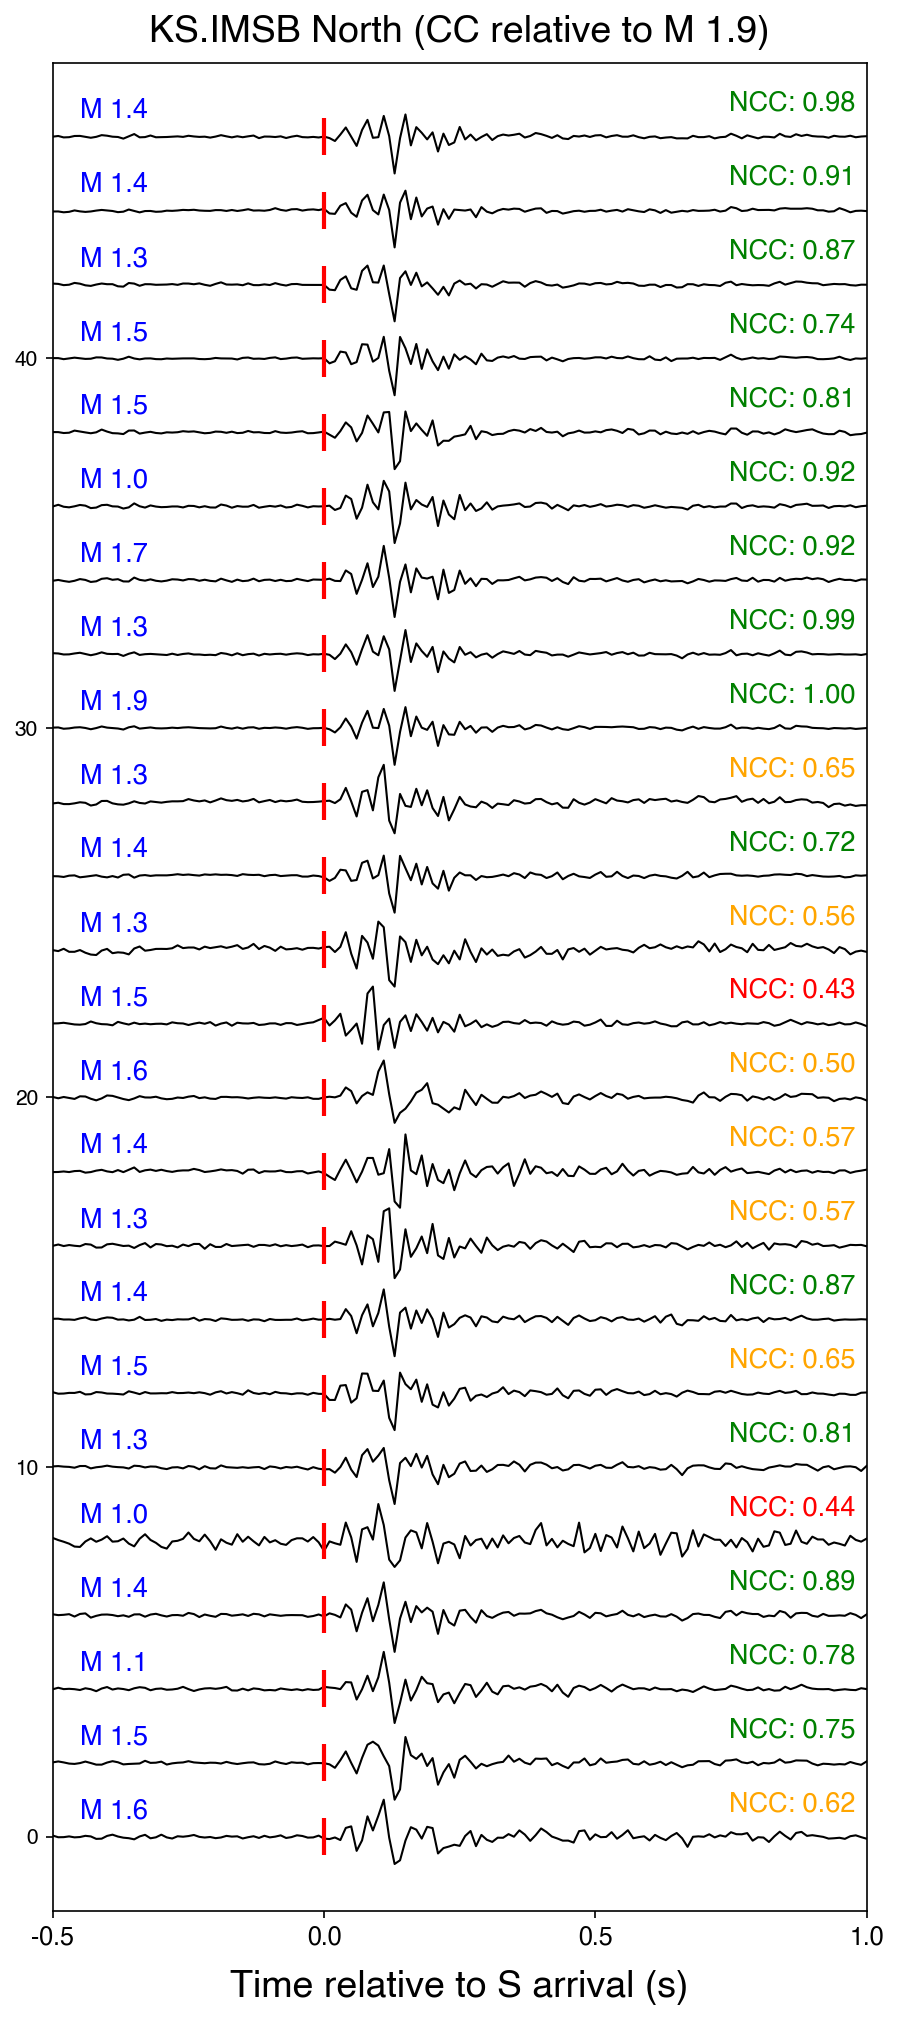

In [6]:
ncc_list = []  # 최대 NCC 값을 저장할 리스트
shift_list = [] # 계산된 시간 이동 값을 저장할 리스트
count_list = []
magnitude_list = []

# --- 2.1. 이동(shift) 파라미터 정의 ---
template_duration = 1.0 - (-0.5) # 템플릿 윈도우 길이 (4.0초)
max_shift_sec = 0.5  # P-pick 기준 좌/우로 최대 0.5초까지 이동 허용

plt.figure(figsize=(7, 16), dpi=150) # 텍스트 추가를 위해 가로 폭 약간 늘림
plt.title(f"KS.IMSB North (CC relative to M 1.9)", fontsize=18, pad=10)
count = 0

if template_slice:
    dt_template = template_slice.stats.delta # 템플릿의 샘플링 간격
    npts_template = len(template_slice.data)
    
    # 0-lag (이동 없음)에 해당하는 인덱스 계산
    zero_lag_index = int(max_shift_sec / dt_template)

    for i in range(len(sacfile_list)):
        tr_N = read(sacfile_list[i])[0]
        mag = magnitudes[i]
        
        try:
            s_time = tr_N.stats.starttime - tr_N.stats.sac.b + tr_N.stats.sac.t0
            
            # --- 2.2. NCC 계산용 '데이터' 파형 처리 ---
            # 템플릿(4초)이 좌/우로 0.5초 움직일 수 있도록 더 긴 윈도우(5초)를 자름
            data_slice = tr_N.copy().detrend("demean").taper(0.05).filter(
                "highpass", freq=1, corners=6, zerophase=True
            ).slice(
                s_time - 0.5 - max_shift_sec,  # s_time - 1.0
                s_time + 1.0 + max_shift_sec   # s_time + 4.0
            ).detrend("demean")

            # 샘플링 레이트가 다른 경우 건너뛰기 (또는 resample)
            if not np.isclose(data_slice.stats.delta, dt_template):
                print(f"Skipping {sacfile_list[i]}: 샘플링 레이트 불일치.")
                continue

            # --- 2.3. 최대 NCC 계산 (템플릿 슬라이딩) ---
            # correlate_template(data, template)
            ncc_values = correlate_template(data_slice.data, template_slice.data)
            
            if len(ncc_values) == 0:
                print(f"Skipping {sacfile_list[i]}: 상관 계수 계산 실패.")
                continue

            # 최대 NCC 값과 해당 인덱스 찾기
            max_ncc_index = np.argmax(ncc_values)
            ncc_value = ncc_values[max_ncc_index]
            
            # P-pick 기준 '0-lag' 인덱스로부터의 샘플 차이 계산
            shift_in_samples = max_ncc_index - zero_lag_index
            time_shift = shift_in_samples * dt_template # 초 단위 시간 이동
            
            ncc_list.append(ncc_value)
            shift_list.append(time_shift)
            magnitude_list.append(mag)

            # --- 2.4. 플로팅용 파형 처리 (시간 이동 적용) ---
            # 계산된 time_shift를 원래 s_time에 더해 '보정된' 윈도우를 다시 자름
            shifted_s_time = s_time + time_shift 
            
            plot_trace = tr_N.copy().detrend("demean").taper(0.05).filter(
                "highpass", freq=1, corners=6, zerophase=True
            ).slice(
                shifted_s_time - 0.5, # 보정된 S파 시간 기준 -0.5초
                shifted_s_time + 1.0  # 보정된 S파 시간 기준 +3.5초
            ).detrend("demean").normalize() # 플로팅을 위해 정규화

            # --- 2.5. 플로팅 ---
            plt.plot(plot_trace.times(), plot_trace.data + 2 * count, color="k", lw=1)
            plt.vlines(x=0.5, ymin=2 * count - 0.5, ymax=2 * count + 0.5, color="r", lw=2)
            
            # 매그니튜드 텍스트
            plt.text(x=0.05, y=2 * count + 0.5, s=f"M {mag:.1f}", color="b", fontsize=13)
            
            # NCC 값 텍스트
            ncc_color = 'g' if ncc_value > 0.7 else ('orange' if ncc_value > 0.5 else 'r')
            plt.text(x=1.48, y=2 * count + 0.7, s=f"NCC: {ncc_value:.2f}", 
                     color=ncc_color, fontsize=13, horizontalalignment='right')

            # 시간 이동(Shift) 텍스트
            shift_color = 'gray' if np.isclose(time_shift, 0, atol=dt_template) else 'k'
            # plt.text(x=1.48, y=2 * count + 0.2, s=f"Shift: {time_shift:+.2f}s", 
            #          color=shift_color, fontsize=11, horizontalalignment='right')

            count_list.append(count)
            count += 1
            
        except Exception as e:
            print(f"Skipping file {sacfile_list[i]} due to error: {e}, Magnitude: M {mag:.1f}")
            pass
    
    plt.xlim(0, 1.5)
    plt.ylim(-2, 2 * count) 
    plt.xticks(np.arange(0.0, 2.0, 0.5), np.arange(-0.5, 1.5, 0.5), fontsize=12)
    plt.xlabel("Time relative to S arrival (s)", fontsize=18, labelpad=10)
    plt.show();

else:
    print("템플릿 파형이 없어 NCC 계산을 진행할 수 없습니다.")

Group 1 (Before): Mean=0.89, Std=0.08
Group 2 (After):  Mean=0.65, Std=0.14


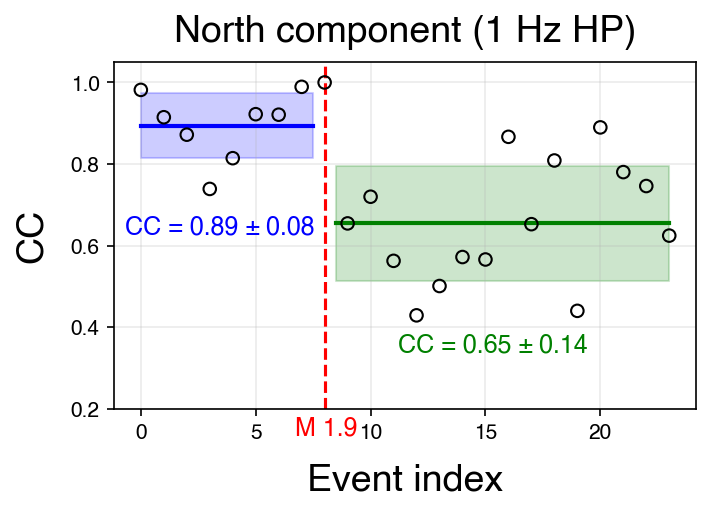

In [7]:
x_data=count_list
y_data=ncc_list[::-1]

x_split_index=8

y_group1=y_data[0:x_split_index]
mean1=np.mean(y_group1)
std1=np.std(y_group1)

y_group2=y_data[x_split_index + 1:]
mean2=np.mean(y_group2)
std2=np.std(y_group2)

print(f"Group 1 (Before): Mean={mean1:.2f}, Std={std1:.2f}")
print(f"Group 2 (After):  Mean={mean2:.2f}, Std={std2:.2f}")

plt.figure(figsize=(5, 3), dpi=150)

plt.title("North component (1 Hz HP)", fontsize=18, pad=10)

x_min=min(x_data)
x_max=max(x_data)

x_range1=[x_min, x_split_index-0.5]
plt.fill_between(x_range1, mean1-std1, mean1+std1, color='b', alpha=0.2, zorder=1)
plt.plot(x_range1, [mean1, mean1], color='blue', linestyle='-', lw=2, zorder=2)
plt.text(s=f"CC = {mean1:.2f} ± {std1:.2f}", x=-0.7, y=0.63, fontsize=12, color="b")

x_range2=[x_split_index+0.5, x_max]
plt.fill_between(x_range2, mean2-std2, mean2+std2, color='g', alpha=0.2, zorder=1)
plt.plot(x_range2, [mean2, mean2], color='green', linestyle='-', lw=2, zorder=2)
plt.text(s=f"CC = {mean2:.2f} ± {std2:.2f}", x=11.2, y=0.34, fontsize=12, color="g")

plt.text(s="M 1.9", x=6.7, y=0.135, fontsize=12, color="r")

plt.scatter(x_data, y_data, color="k", lw=1, facecolors="none", zorder=10)

plt.axvline(x=8, linestyle="--", color="r")
plt.ylim(0.2, 1.05)
plt.xlabel("Event index", fontsize=18, labelpad=10)
plt.ylabel("CC", fontsize=18, labelpad=10)
plt.grid(alpha=0.25)
plt.show();

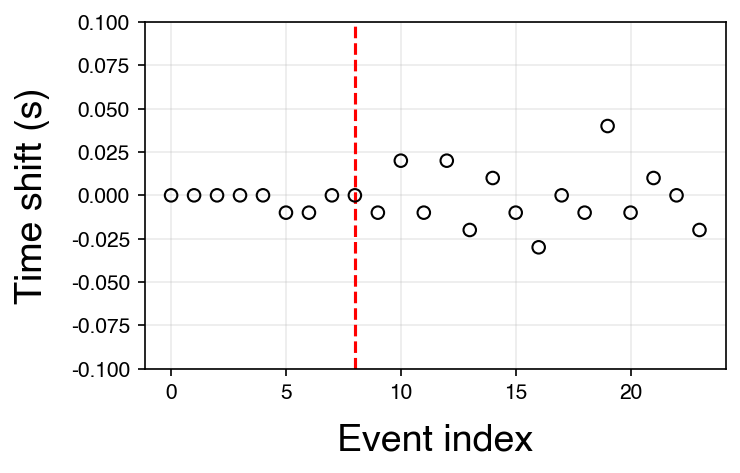

In [58]:
x_data=count_list
y_data=shift_list[::-1]

x_split_index=8

plt.figure(figsize=(5, 3), dpi=150)
x_min=min(x_data)
x_max=max(x_data)
plt.scatter(x_data, y_data, color="k", lw=1, facecolors="none", zorder=10)
plt.axvline(x=8, linestyle="--", color="r")
plt.ylim(-0.1, 0.1)
plt.xlabel("Event index", fontsize=18, labelpad=10)
plt.ylabel("Time shift (s)", fontsize=18, labelpad=10)
plt.grid(alpha=0.25)
plt.show();

In [59]:
np.median(shift_list), np.mean(shift_list)

(0.0, -0.0016666666666666668)

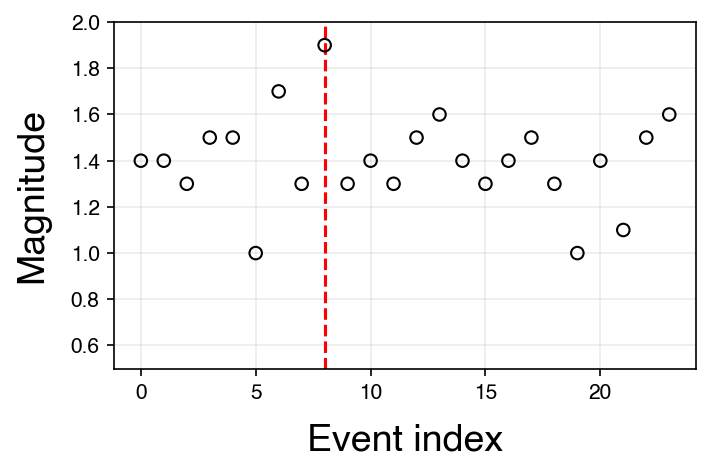

In [60]:
x_data=count_list
y_data=magnitude_list[::-1]

x_split_index=8

plt.figure(figsize=(5, 3), dpi=150)
x_min=min(x_data)
x_max=max(x_data)
plt.scatter(x_data, y_data, color="k", lw=1, facecolors="none", zorder=10)
plt.axvline(x=8, linestyle="--", color="r")
plt.ylim(0.5, 2.0)
plt.xlabel("Event index", fontsize=18, labelpad=10)
plt.ylabel("Magnitude", fontsize=18, labelpad=10)
plt.grid(alpha=0.25)
plt.show();

In [61]:
y_group1=y_data[0:x_split_index]
mean1=np.mean(y_group1)
std1=np.std(y_group1)

y_group2=y_data[x_split_index + 1:]
mean2=np.mean(y_group2)
std2=np.std(y_group2)

print(f"Group 1 (Before): Mean={mean1:.2f}, Std={std1:.2f}")
print(f"Group 2 (After):  Mean={mean2:.2f}, Std={std2:.2f}")

Group 1 (Before): Mean=1.39, Std=0.19
Group 2 (After):  Mean=1.37, Std=0.16


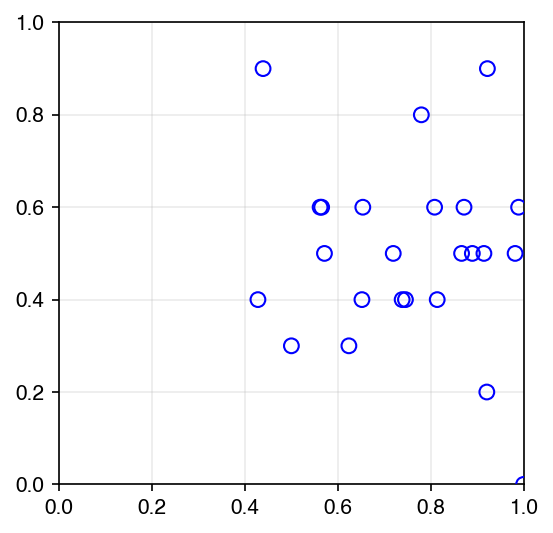

In [62]:
plt.figure(figsize=(4, 4), dpi=150)
plt.scatter(ncc_list, 1.9-np.array(magnitude_list), color="b", facecolors="none", s=50, lw=1, zorder=10)
plt.xlim(0.0, 1.0)
plt.ylim(0.0, 1.0)
plt.grid(alpha=0.25)
plt.show();

### Bandpass filter (5-25 Hz)

In [63]:
sacfile_list = sorted(glob("/home/msseo/works/72.2025_Imsil_swarm/waveforms_100km/20*/*IMSB*HHN.sac"))[::-1]

try:
    magnitudes = np.array(event_catalog["Magnitude"])[::-1]
except NameError:
    print("오류: 'event_catalog'가 정의되지 않았습니다. 샘플 데이터를 생성합니다.")
    # 이 부분은 사용자의 실제 데이터로 대체되어야 합니다.
    magnitudes = np.random.uniform(0.5, 3.0, len(sacfile_list))
    magnitudes[5] = 1.9 # 테스트용 1.9 매그니튜드

# --- 1. 템플릿 파형 (M 1.9) 찾기 및 처리 ---
template_slice = None
target_mag = 1.9

try:
    # np.isclose를 사용해 부동소수점 비교
    template_index = np.where(np.isclose(magnitudes, target_mag))[0][0]
    template_sacfile = sacfile_list[template_index]
    
    # 템플릿 파일 처리 (기존 루프와 *동일하게* 처리)
    tr_template = read(template_sacfile)[0]
    s_time_template = tr_template.stats.starttime - tr_template.stats.sac.b + tr_template.stats.sac.t0
    
    # !! 중요: NCC 계산용 데이터이므로 .normalize() 제거 !!
    template_slice = tr_template.copy().detrend("demean").taper(0.05).filter(
        "bandpass", freqmin=5, freqmax=25, corners=6, zerophase=True
    ).slice(
        s_time_template - 0.5, s_time_template + 1.0
    ).detrend("demean")
    
    print(f"✅ 템플릿 파형 생성 완료: {template_sacfile} (M {magnitudes[template_index]:.1f})")

except IndexError:
    print(f"❌ 오류: 규모 {target_mag}에 가까운 이벤트를 찾을 수 없습니다.")
except Exception as e:
    print(f"❌ 템플릿 처리 중 오류 발생: {e}")

✅ 템플릿 파형 생성 완료: /home/msseo/works/72.2025_Imsil_swarm/waveforms_100km/20251102203835/20251102203835.KS.IMSB.HHN.sac (M 1.9)


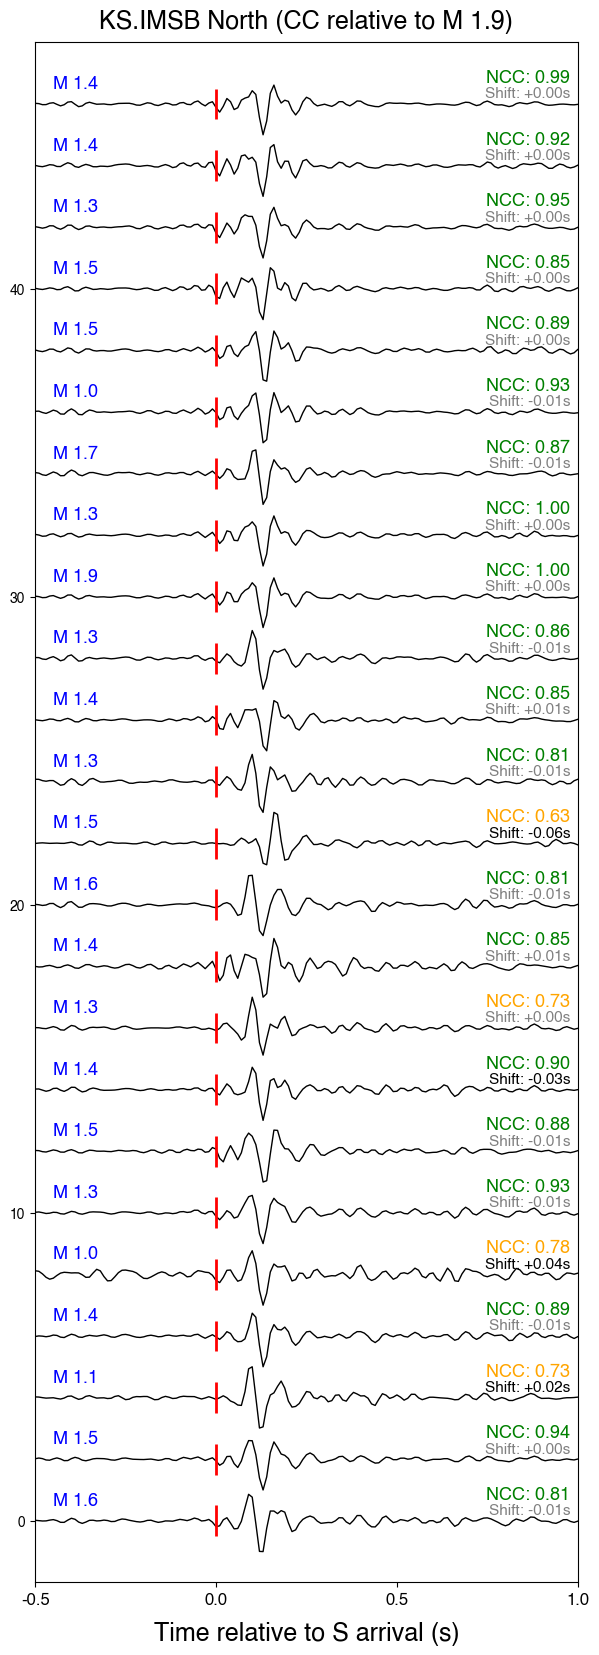

In [64]:
ncc_list = []  # 최대 NCC 값을 저장할 리스트
shift_list = [] # 계산된 시간 이동 값을 저장할 리스트
count_list = []
magnitude_list = []

# --- 2.1. 이동(shift) 파라미터 정의 ---
template_duration = 1.0 - (-0.5) # 템플릿 윈도우 길이 (4.0초)
max_shift_sec = 0.5  # P-pick 기준 좌/우로 최대 0.5초까지 이동 허용

plt.figure(figsize=(7, 20)) # 텍스트 추가를 위해 가로 폭 약간 늘림
plt.title(f"KS.IMSB North (CC relative to M 1.9)", fontsize=18, pad=10)
count = 0

if template_slice:
    dt_template = template_slice.stats.delta # 템플릿의 샘플링 간격
    npts_template = len(template_slice.data)
    
    # 0-lag (이동 없음)에 해당하는 인덱스 계산
    zero_lag_index = int(max_shift_sec / dt_template)

    for i in range(len(sacfile_list)):
        tr_N = read(sacfile_list[i])[0]
        mag = magnitudes[i]
        
        try:
            s_time = tr_N.stats.starttime - tr_N.stats.sac.b + tr_N.stats.sac.t0
            
            # --- 2.2. NCC 계산용 '데이터' 파형 처리 ---
            # 템플릿(4초)이 좌/우로 0.5초 움직일 수 있도록 더 긴 윈도우(5초)를 자름
            data_slice = tr_N.copy().detrend("demean").taper(0.05).filter(
                "bandpass", freqmin=5, freqmax=25, corners=6, zerophase=True
            ).slice(
                s_time - 0.5 - max_shift_sec,  # s_time - 1.0
                s_time + 1.0 + max_shift_sec   # s_time + 4.0
            ).detrend("demean")

            # 샘플링 레이트가 다른 경우 건너뛰기 (또는 resample)
            if not np.isclose(data_slice.stats.delta, dt_template):
                print(f"Skipping {sacfile_list[i]}: 샘플링 레이트 불일치.")
                continue

            # --- 2.3. 최대 NCC 계산 (템플릿 슬라이딩) ---
            # correlate_template(data, template)
            ncc_values = correlate_template(data_slice.data, template_slice.data)
            
            if len(ncc_values) == 0:
                print(f"Skipping {sacfile_list[i]}: 상관 계수 계산 실패.")
                continue

            # 최대 NCC 값과 해당 인덱스 찾기
            max_ncc_index = np.argmax(ncc_values)
            ncc_value = ncc_values[max_ncc_index]
            
            # P-pick 기준 '0-lag' 인덱스로부터의 샘플 차이 계산
            shift_in_samples = max_ncc_index - zero_lag_index
            time_shift = shift_in_samples * dt_template # 초 단위 시간 이동
            
            ncc_list.append(ncc_value)
            shift_list.append(time_shift)
            magnitude_list.append(mag)

            # --- 2.4. 플로팅용 파형 처리 (시간 이동 적용) ---
            # 계산된 time_shift를 원래 s_time에 더해 '보정된' 윈도우를 다시 자름
            shifted_s_time = s_time + time_shift 
            
            plot_trace = tr_N.copy().detrend("demean").taper(0.05).filter(
                "bandpass", freqmin=5, freqmax=25, corners=6, zerophase=True
            ).slice(
                shifted_s_time - 0.5, # 보정된 S파 시간 기준 -0.5초
                shifted_s_time + 1.0  # 보정된 S파 시간 기준 +3.5초
            ).detrend("demean").normalize() # 플로팅을 위해 정규화

            # --- 2.5. 플로팅 ---
            plt.plot(plot_trace.times(), plot_trace.data + 2 * count, color="k", lw=1)
            plt.vlines(x=0.5, ymin=2 * count - 0.5, ymax=2 * count + 0.5, color="r", lw=2)
            
            # 매그니튜드 텍스트
            plt.text(x=0.05, y=2 * count + 0.5, s=f"M {mag:.1f}", color="b", fontsize=13)
            
            # NCC 값 텍스트
            ncc_color = 'g' if ncc_value > 0.8 else ('orange' if ncc_value > 0.5 else 'r')
            plt.text(x=1.48, y=2 * count + 0.7, s=f"NCC: {ncc_value:.2f}", 
                     color=ncc_color, fontsize=13, horizontalalignment='right')

            # 시간 이동(Shift) 텍스트
            shift_color = 'gray' if np.isclose(time_shift, 0, atol=dt_template) else 'k'
            plt.text(x=1.48, y=2 * count + 0.2, s=f"Shift: {time_shift:+.2f}s", 
                     color=shift_color, fontsize=11, horizontalalignment='right')

            count_list.append(count)
            count += 1
            
        except Exception as e:
            print(f"Skipping file {sacfile_list[i]} due to error: {e}, Magnitude: M {mag:.1f}")
            pass
    
    plt.xlim(0, 1.5)
    plt.ylim(-2, 2 * count) 
    plt.xticks(np.arange(0.0, 2.0, 0.5), np.arange(-0.5, 1.5, 0.5), fontsize=12)
    plt.xlabel("Time relative to S arrival (s)", fontsize=18, labelpad=10)
    plt.show();

else:
    print("템플릿 파형이 없어 NCC 계산을 진행할 수 없습니다.")

Group 1 (Before): Mean=0.92, Std=0.05
Group 2 (After):  Mean=0.83, Std=0.08


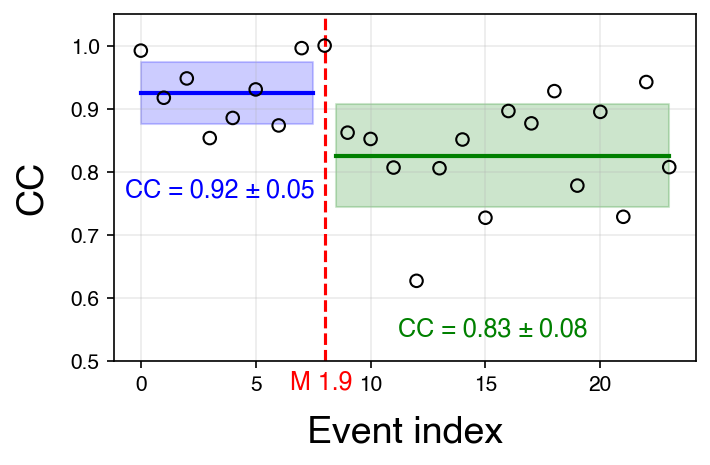

In [80]:
x_data=count_list
y_data=ncc_list[::-1]

x_split_index=8

y_group1=y_data[0:x_split_index]
mean1=np.mean(y_group1)
std1=np.std(y_group1)

y_group2=y_data[x_split_index + 1:]
mean2=np.mean(y_group2)
std2=np.std(y_group2)

print(f"Group 1 (Before): Mean={mean1:.2f}, Std={std1:.2f}")
print(f"Group 2 (After):  Mean={mean2:.2f}, Std={std2:.2f}")

plt.figure(figsize=(5, 3), dpi=150)

x_min=min(x_data)
x_max=max(x_data)

x_range1=[x_min, x_split_index-0.5]
plt.fill_between(x_range1, mean1-std1, mean1+std1, color='b', alpha=0.2, zorder=1)
plt.plot(x_range1, [mean1, mean1], color='blue', linestyle='-', lw=2, zorder=2)
plt.text(s=f"CC = {mean1:.2f} ± {std1:.2f}", x=-0.7, y=0.76, fontsize=12, color="b")

x_range2=[x_split_index+0.5, x_max]
plt.fill_between(x_range2, mean2-std2, mean2+std2, color='g', alpha=0.2, zorder=1)
plt.plot(x_range2, [mean2, mean2], color='green', linestyle='-', lw=2, zorder=2)
plt.text(s=f"CC = {mean2:.2f} ± {std2:.2f}", x=11.2, y=0.54, fontsize=12, color="g")

plt.text(s="M 1.9", x=6.5, y=0.455, fontsize=12, color="r")

plt.scatter(x_data, y_data, color="k", lw=1, facecolors="none", zorder=10)

plt.axvline(x=8, linestyle="--", color="r")
plt.ylim(0.5, 1.05)
plt.xlabel("Event index", fontsize=18, labelpad=10)
plt.ylabel("CC", fontsize=18, labelpad=10)
plt.grid(alpha=0.25)
plt.show();

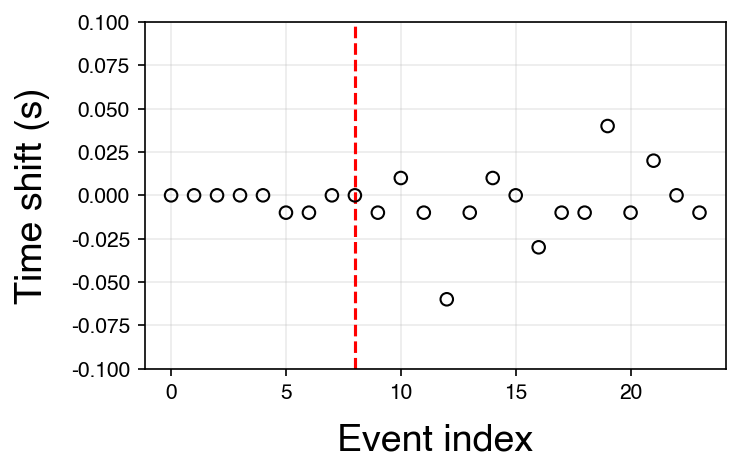

In [81]:
x_data=count_list
y_data=shift_list[::-1]

x_split_index=8

plt.figure(figsize=(5, 3), dpi=150)
x_min=min(x_data)
x_max=max(x_data)
plt.scatter(x_data, y_data, color="k", lw=1, facecolors="none", zorder=10)
plt.axvline(x=8, linestyle="--", color="r")
plt.ylim(-0.1, 0.1)
plt.xlabel("Event index", fontsize=18, labelpad=10)
plt.ylabel("Time shift (s)", fontsize=18, labelpad=10)
plt.grid(alpha=0.25)
plt.show();

### Bandpass filter (2-10 Hz)

In [83]:
sacfile_list = sorted(glob("/home/msseo/works/72.2025_Imsil_swarm/waveforms_100km/20*/*IMSB*HHN.sac"))[::-1]

try:
    magnitudes = np.array(event_catalog["Magnitude"])[::-1]
except NameError:
    print("오류: 'event_catalog'가 정의되지 않았습니다. 샘플 데이터를 생성합니다.")
    # 이 부분은 사용자의 실제 데이터로 대체되어야 합니다.
    magnitudes = np.random.uniform(0.5, 3.0, len(sacfile_list))
    magnitudes[5] = 1.9 # 테스트용 1.9 매그니튜드

# --- 1. 템플릿 파형 (M 1.9) 찾기 및 처리 ---
template_slice = None
target_mag = 1.9

try:
    # np.isclose를 사용해 부동소수점 비교
    template_index = np.where(np.isclose(magnitudes, target_mag))[0][0]
    template_sacfile = sacfile_list[template_index]
    
    # 템플릿 파일 처리 (기존 루프와 *동일하게* 처리)
    tr_template = read(template_sacfile)[0]
    s_time_template = tr_template.stats.starttime - tr_template.stats.sac.b + tr_template.stats.sac.t0
    
    # !! 중요: NCC 계산용 데이터이므로 .normalize() 제거 !!
    template_slice = tr_template.copy().detrend("demean").taper(0.05).filter(
        "bandpass", freqmin=2, freqmax=10, corners=6, zerophase=True
    ).slice(
        s_time_template - 0.5, s_time_template + 1.0
    ).detrend("demean")
    
    print(f"✅ 템플릿 파형 생성 완료: {template_sacfile} (M {magnitudes[template_index]:.1f})")

except IndexError:
    print(f"❌ 오류: 규모 {target_mag}에 가까운 이벤트를 찾을 수 없습니다.")
except Exception as e:
    print(f"❌ 템플릿 처리 중 오류 발생: {e}")

✅ 템플릿 파형 생성 완료: /home/msseo/works/72.2025_Imsil_swarm/waveforms_100km/20251102203835/20251102203835.KS.IMSB.HHN.sac (M 1.9)


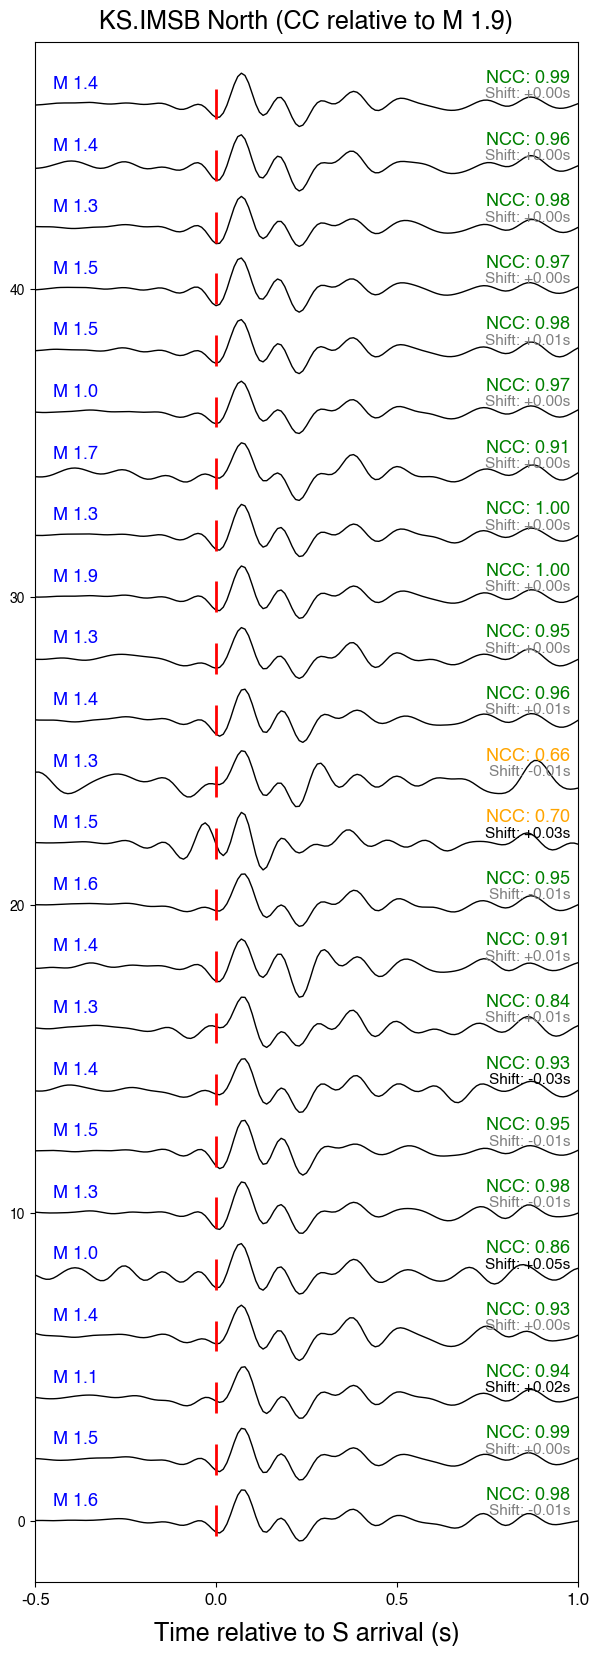

In [84]:
ncc_list = []  # 최대 NCC 값을 저장할 리스트
shift_list = [] # 계산된 시간 이동 값을 저장할 리스트
count_list = []
magnitude_list = []

# --- 2.1. 이동(shift) 파라미터 정의 ---
template_duration = 1.0 - (-0.5) # 템플릿 윈도우 길이 (4.0초)
max_shift_sec = 0.5  # P-pick 기준 좌/우로 최대 0.5초까지 이동 허용

plt.figure(figsize=(7, 20)) # 텍스트 추가를 위해 가로 폭 약간 늘림
plt.title(f"KS.IMSB North (CC relative to M 1.9)", fontsize=18, pad=10)
count = 0

if template_slice:
    dt_template = template_slice.stats.delta # 템플릿의 샘플링 간격
    npts_template = len(template_slice.data)
    
    # 0-lag (이동 없음)에 해당하는 인덱스 계산
    zero_lag_index = int(max_shift_sec / dt_template)

    for i in range(len(sacfile_list)):
        tr_N = read(sacfile_list[i])[0]
        mag = magnitudes[i]
        
        try:
            s_time = tr_N.stats.starttime - tr_N.stats.sac.b + tr_N.stats.sac.t0
            
            # --- 2.2. NCC 계산용 '데이터' 파형 처리 ---
            # 템플릿(4초)이 좌/우로 0.5초 움직일 수 있도록 더 긴 윈도우(5초)를 자름
            data_slice = tr_N.copy().detrend("demean").taper(0.05).filter(
                "bandpass", freqmin=2, freqmax=10, corners=6, zerophase=True
            ).slice(
                s_time - 0.5 - max_shift_sec,  # s_time - 1.0
                s_time + 1.0 + max_shift_sec   # s_time + 4.0
            ).detrend("demean")

            # 샘플링 레이트가 다른 경우 건너뛰기 (또는 resample)
            if not np.isclose(data_slice.stats.delta, dt_template):
                print(f"Skipping {sacfile_list[i]}: 샘플링 레이트 불일치.")
                continue

            # --- 2.3. 최대 NCC 계산 (템플릿 슬라이딩) ---
            # correlate_template(data, template)
            ncc_values = correlate_template(data_slice.data, template_slice.data)
            
            if len(ncc_values) == 0:
                print(f"Skipping {sacfile_list[i]}: 상관 계수 계산 실패.")
                continue

            # 최대 NCC 값과 해당 인덱스 찾기
            max_ncc_index = np.argmax(ncc_values)
            ncc_value = ncc_values[max_ncc_index]
            
            # P-pick 기준 '0-lag' 인덱스로부터의 샘플 차이 계산
            shift_in_samples = max_ncc_index - zero_lag_index
            time_shift = shift_in_samples * dt_template # 초 단위 시간 이동
            
            ncc_list.append(ncc_value)
            shift_list.append(time_shift)
            magnitude_list.append(mag)

            # --- 2.4. 플로팅용 파형 처리 (시간 이동 적용) ---
            # 계산된 time_shift를 원래 s_time에 더해 '보정된' 윈도우를 다시 자름
            shifted_s_time = s_time + time_shift 
            
            plot_trace = tr_N.copy().detrend("demean").taper(0.05).filter(
                "bandpass", freqmin=2, freqmax=10, corners=6, zerophase=True
            ).slice(
                shifted_s_time - 0.5, # 보정된 S파 시간 기준 -0.5초
                shifted_s_time + 1.0  # 보정된 S파 시간 기준 +3.5초
            ).detrend("demean").normalize() # 플로팅을 위해 정규화

            # --- 2.5. 플로팅 ---
            plt.plot(plot_trace.times(), plot_trace.data + 2 * count, color="k", lw=1)
            plt.vlines(x=0.5, ymin=2 * count - 0.5, ymax=2 * count + 0.5, color="r", lw=2)
            
            # 매그니튜드 텍스트
            plt.text(x=0.05, y=2 * count + 0.5, s=f"M {mag:.1f}", color="b", fontsize=13)
            
            # NCC 값 텍스트
            ncc_color = 'g' if ncc_value > 0.8 else ('orange' if ncc_value > 0.5 else 'r')
            plt.text(x=1.48, y=2 * count + 0.7, s=f"NCC: {ncc_value:.2f}", 
                     color=ncc_color, fontsize=13, horizontalalignment='right')

            # 시간 이동(Shift) 텍스트
            shift_color = 'gray' if np.isclose(time_shift, 0, atol=dt_template) else 'k'
            plt.text(x=1.48, y=2 * count + 0.2, s=f"Shift: {time_shift:+.2f}s", 
                     color=shift_color, fontsize=11, horizontalalignment='right')

            count_list.append(count)
            count += 1
            
        except Exception as e:
            print(f"Skipping file {sacfile_list[i]} due to error: {e}, Magnitude: M {mag:.1f}")
            pass
    
    plt.xlim(0, 1.5)
    plt.ylim(-2, 2 * count) 
    plt.xticks(np.arange(0.0, 2.0, 0.5), np.arange(-0.5, 1.5, 0.5), fontsize=12)
    plt.xlabel("Time relative to S arrival (s)", fontsize=18, labelpad=10)
    plt.show();

else:
    print("템플릿 파형이 없어 NCC 계산을 진행할 수 없습니다.")

Group 1 (Before): Mean=0.97, Std=0.03
Group 2 (After):  Mean=0.90, Std=0.09


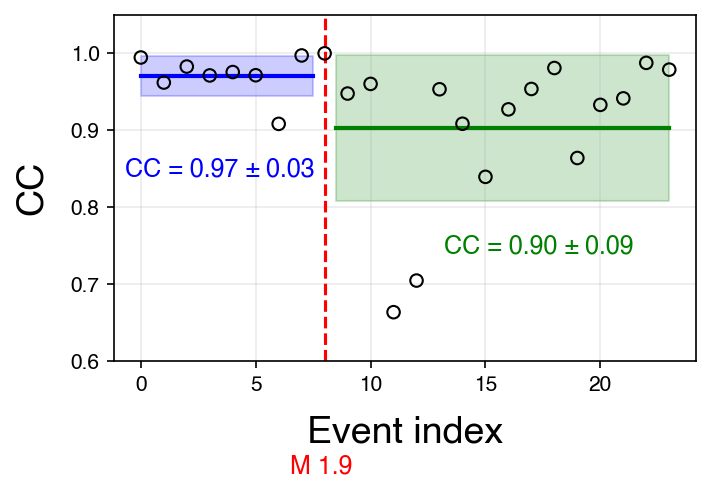

In [93]:
x_data=count_list
y_data=ncc_list[::-1]

x_split_index=8

y_group1=y_data[0:x_split_index]
mean1=np.mean(y_group1)
std1=np.std(y_group1)

y_group2=y_data[x_split_index + 1:]
mean2=np.mean(y_group2)
std2=np.std(y_group2)

print(f"Group 1 (Before): Mean={mean1:.2f}, Std={std1:.2f}")
print(f"Group 2 (After):  Mean={mean2:.2f}, Std={std2:.2f}")

plt.figure(figsize=(5, 3), dpi=150)

x_min=min(x_data)
x_max=max(x_data)

x_range1=[x_min, x_split_index-0.5]
plt.fill_between(x_range1, mean1-std1, mean1+std1, color='b', alpha=0.2, zorder=1)
plt.plot(x_range1, [mean1, mean1], color='blue', linestyle='-', lw=2, zorder=2)
plt.text(s=f"CC = {mean1:.2f} ± {std1:.2f}", x=-0.7, y=0.84, fontsize=12, color="b")

x_range2=[x_split_index+0.5, x_max]
plt.fill_between(x_range2, mean2-std2, mean2+std2, color='g', alpha=0.2, zorder=1)
plt.plot(x_range2, [mean2, mean2], color='green', linestyle='-', lw=2, zorder=2)
plt.text(s=f"CC = {mean2:.2f} ± {std2:.2f}", x=13.2, y=0.74, fontsize=12, color="g")

plt.text(s="M 1.9", x=6.5, y=0.455, fontsize=12, color="r")

plt.scatter(x_data, y_data, color="k", lw=1, facecolors="none", zorder=10)

plt.axvline(x=8, linestyle="--", color="r")
plt.ylim(0.6, 1.05)
plt.xlabel("Event index", fontsize=18, labelpad=10)
plt.ylabel("CC", fontsize=18, labelpad=10)
plt.grid(alpha=0.25)
plt.show();

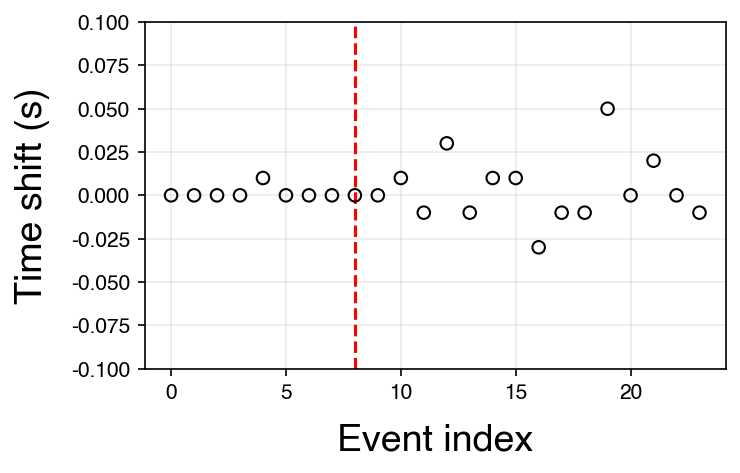

In [94]:
x_data=count_list
y_data=shift_list[::-1]

x_split_index=8

plt.figure(figsize=(5, 3), dpi=150)
x_min=min(x_data)
x_max=max(x_data)
plt.scatter(x_data, y_data, color="k", lw=1, facecolors="none", zorder=10)
plt.axvline(x=8, linestyle="--", color="r")
plt.ylim(-0.1, 0.1)
plt.xlabel("Event index", fontsize=18, labelpad=10)
plt.ylabel("Time shift (s)", fontsize=18, labelpad=10)
plt.grid(alpha=0.25)
plt.show();